[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_close/BA_L1_close.ipynb)

# BA_L1_close: Price Differences across Exchanges and the Daily Close

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Two conventions behind a daily Bitcoin price: the gap of the daily close between three exchanges (Bitstamp, Kraken, Coinbase), in basis points, December 2024 to October 2026; and the correlation of Bitcoin and S&P 500 daily returns, 2021 to 2026, as a function of the hour (UTC) at which the Bitcoin day closes, with the change of the daily return between the New York close and the midnight close.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

A daily price of Bitcoin rests on two conventions: the exchange on which it is observed and the hour at which the day
closes.

- **Exchange.** The gap between two exchanges on day $t$ is $10^4 \ln(P^{A}_t / P^{B}_t)$, in basis points (bp, 0.01%),
  with $P_t$ the daily close in US dollars. All three exchanges end the day at midnight UTC.
- **Closing hour.** For each hour $h$ (UTC), the Bitcoin return of an S&P 500 trading day is the log change of the price
  at hour $h$ between consecutive trading days; hour 24 is the midnight after the day, the close of the data vendor. The
  chart shows its correlation with the S&P 500 return of the same day. The New York close is 16:00 local time,
  21:00 UTC in winter and 20:00 UTC in summer.

**How to read the chart.** Left: the three exchanges agree at the close within a few basis points. Right: the
correlation with the S&P 500 depends on the closing hour; a close taken before the New York session leaves out the
hours in which the two markets move together.

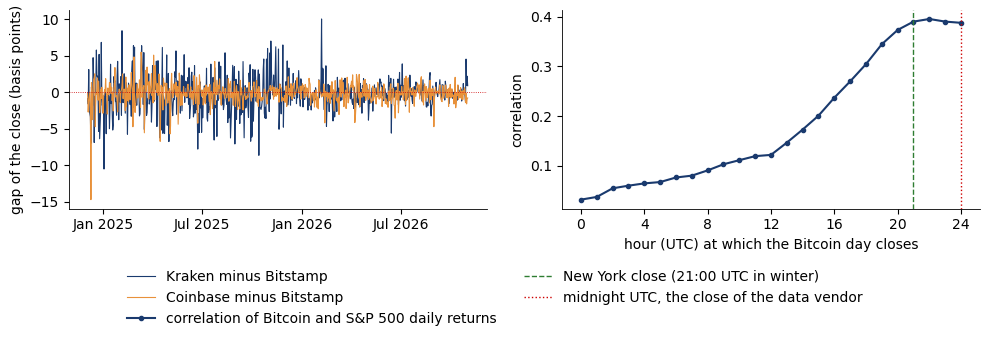

Exchanges: 698 days, 03 December 2024 to 31 October 2026
  Kraken minus Bitstamp: median absolute gap 1.2 bp, 95% below 5.6 bp, largest 10.5 bp (02 January 2025)
  Coinbase minus Bitstamp: median absolute gap 0.8 bp, 95% below 2.7 bp, largest 14.7 bp (09 December 2024)
Closing hour: 1449 S&P 500 trading days, 05 January 2021 to 30 October 2026
  correlation with the S&P 500: close at 00:00 UTC 0.03, 12:00 0.12, 21:00 0.39, midnight after the day 0.39; at the New York close 0.39
  daily return with the New York close against the midnight close: median absolute difference 67 bp, mean 103 bp, 95% below 306 bp


In [5]:
# (a) the daily close of Bitcoin on three exchanges (USD pairs; the day ends at midnight UTC on all three)
ex = pd.read_csv(data_file('market', 'BTC_close_exchanges.csv'), parse_dates=['date']).set_index('date')
gap = pd.DataFrame({'Kraken': 1e4 * np.log(ex['Kraken'] / ex['Bitstamp']),
                    'Coinbase': 1e4 * np.log(ex['Coinbase'] / ex['Bitstamp'])})      # basis points against Bitstamp

# (b) Bitcoin at every hour (UTC); price_at(t) is the last hourly close before time t
ph = hourly('BTC-USD.CC')
ph = ph[~ph.index.duplicated(keep='last')].sort_index()
ph = ph.reindex(pd.date_range(ph.index[0], ph.index[-1], freq='h')).ffill(limit=3)


def price_at(times):
    return ph.reindex(pd.DatetimeIndex(times) - pd.Timedelta(hours=1)).values


sp = daily('GSPC.INDX').loc['2021-01-04':'2026-10-30']
r_sp = np.log(sp).diff()


def btc_return(hour):
    # log return of Bitcoin between the same hour (UTC) of consecutive S&P 500 trading days; hour 24 = next midnight
    b = pd.Series(price_at([d + pd.Timedelta(hours=hour) for d in sp.index]), index=sp.index)
    return np.log(b).diff()


hours = np.arange(0, 25)
corr_h = pd.Series([btc_return(h).corr(r_sp) for h in hours], index=hours)

# the New York close (16:00 local time) in UTC, with daylight saving
ny = pd.DatetimeIndex([pd.Timestamp(d.date()).tz_localize('America/New_York') + pd.Timedelta(hours=16)
                       for d in sp.index]).tz_convert('UTC').tz_localize(None)
r_ny = np.log(pd.Series(price_at(ny), index=sp.index)).diff()
r_mid = btc_return(24)
both = pd.concat([r_ny, r_mid, r_sp], axis=1, keys=['ny', 'mid', 'sp']).dropna()
dret = 1e4 * (both['ny'] - both['mid']).abs()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(gap.index, gap['Kraken'], color=BLUE, lw=0.8, label='Kraken minus Bitstamp')
ax[0].plot(gap.index, gap['Coinbase'], color=BTC, lw=0.8, label='Coinbase minus Bitstamp')
ax[0].axhline(0, color=RED, lw=0.6, ls=':')
ax[0].set_ylabel('gap of the close (basis points)')
import matplotlib.dates as mdates
ax[0].xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax[1].plot(corr_h.index, corr_h.values, color=BLUE, marker='o', ms=3, label='correlation of Bitcoin and S&P 500 daily returns')
ax[1].axvline(21, color=GREEN, lw=1, ls='--', label='New York close (21:00 UTC in winter)')
ax[1].axvline(24, color=RED, lw=1, ls=':', label='midnight UTC, the close of the data vendor')
ax[1].set_xlabel('hour (UTC) at which the Bitcoin day closes'); ax[1].set_ylabel('correlation')
ax[1].set_xticks([0, 4, 8, 12, 16, 20, 24])
legend_below(fig, ncol=2, bottom=0.20)
save_fig(fig, 'ba_l1_close')

print(f'Exchanges: {len(ex)} days, {ex.index[0]:%d %B %Y} to {ex.index[-1]:%d %B %Y}')
for c in gap:
    print(f'  {c} minus Bitstamp: median absolute gap {gap[c].abs().median():.1f} bp, 95% below {gap[c].abs().quantile(0.95):.1f} bp, '
          f'largest {gap[c].abs().max():.1f} bp ({gap[c].abs().idxmax():%d %B %Y})')
print(f'Closing hour: {len(both)} S&P 500 trading days, {both.index[0]:%d %B %Y} to {both.index[-1]:%d %B %Y}')
print(f'  correlation with the S&P 500: close at 00:00 UTC {corr_h[0]:.2f}, 12:00 {corr_h[12]:.2f}, 21:00 {corr_h[21]:.2f}, '
      f'midnight after the day {corr_h[24]:.2f}; at the New York close {both["ny"].corr(both["sp"]):.2f}')
print(f'  daily return with the New York close against the midnight close: median absolute difference {dret.median():.0f} bp, '
      f'mean {dret.mean():.0f} bp, 95% below {dret.quantile(0.95):.0f} bp')